In [1]:
import sys
sys.path.append("../")

from problems.testfuncs import Quadratic, Rosenbrock2d, RosenbrockNd, Himmelblau, make_quadratic
from optlib.utils import grad_check

import numpy as np

rng = np.random.default_rng(0)


# 1.1 - 1.2

In [2]:
def verifyQuadratic():
    n = 32
    
    # define A such that symmetric and positive definite 
    M = rng.random((n,n), dtype=np.float64)
    A = M.T @ M + n * np.eye(n)
    b = rng.random(n, dtype=np.float64)
    x = rng.random(n, dtype=np.float64)
    
    f = Quadratic(A, b)
    grad = f.grad(x)
    errors = grad_check(f, x, grad, n=8)
    for i, err, _grad in errors:
        if abs(grad.flat[i] - _grad) > 1e-6:
            print("[FAILED] ========================================")            
            print(f"Error at {i}: {err}")
            print(f"Analytical Grad: {grad.flat[i]}, Expected Grad: {_grad}")

In [3]:
def verifyRosenbrock2d():
    a, b = rng.random(), rng.random()
    f = Rosenbrock2d(a, b)
    x, y = rng.random(), rng.random()
    x = np.array([x,y])
    grad = f.grad(x)
    errors = grad_check(f, x, np.array(grad), n=2)
    for i, err, _grad in errors:
        if abs(grad.flat[i] - _grad) > 1e-6:
            print("[FAILED] ========================================")            
            print(f"Error at {i}: {err}")
            print(f"Analytical Grad: {grad.flat[i]}, Expected Grad: {_grad}")

In [4]:
def verifyRosenbrockNd():
    N=32
    f = RosenbrockNd()
    x = rng.random(N)
    
    grad = f.grad(x)
    errors = grad_check(f, x, grad, n=8)
    for i, err, _grad in errors:
        if abs(grad.flat[i] - _grad) > 1e-6:
            print("[FAILED] ========================================")            
            print(f"Error at {i}: {err}")
            print(f"Analytical Grad: {grad.flat[i]}, Expected Grad: {_grad}")

In [5]:
def verifyHimmelblau():
    N=2
    f = Himmelblau()
    x = rng.random(N)
    
    grad = f.grad(x)
    errors = grad_check(f, x, grad, n=2)
    for i, err, _grad in errors:
        if abs(grad.flat[i] - _grad) > 1e-6:
            print("[FAILED] ========================================")            
            print(f"Error at {i}: {err}")
            print(f"Analytical Grad: {grad.flat[i]}, Expected Grad: {_grad}")

In [6]:
verifyQuadratic()
verifyRosenbrock2d()
verifyRosenbrockNd()
verifyHimmelblau()

# 1.3

In [7]:
n=32*32
A_k1    = make_quadratic(n, kappa=1);    assert(np.isclose(np.linalg.cond(A_k1), 1))
A_k10   = make_quadratic(n, kappa=10);   assert(np.isclose(np.linalg.cond(A_k10), 10))
A_k100  = make_quadratic(n, kappa=100);  assert(np.isclose(np.linalg.cond(A_k100), 100))
A_k1000 = make_quadratic(n, kappa=1000); assert(np.isclose(np.linalg.cond(A_k1000), 1000))
A_ks = [A_k1, A_k10, A_k100, A_k1000]

In [8]:
from optlib.first_order import GD

results = []
x0=rng.random(n)
for A, kappa in zip(A_ks, (1,10,100,1000)):
    f = Quadratic(A=A, b=np.zeros(n))
    eigvals = np.linalg.eigvalsh(A)
    step = 2.0 / (eigvals[-1] + eigvals[0])
    # step = 1 / eigvals[-1]
    qcgd = GD(step)
    res = qcgd.minimize(f, x0, tol=1e-8, max_iter=10000)
    results.append(res)
    print(f"CONVERGED?: {res.converged}")
    

CONVERGED?: True
CONVERGED?: True
CONVERGED?: True
CONVERGED?: False


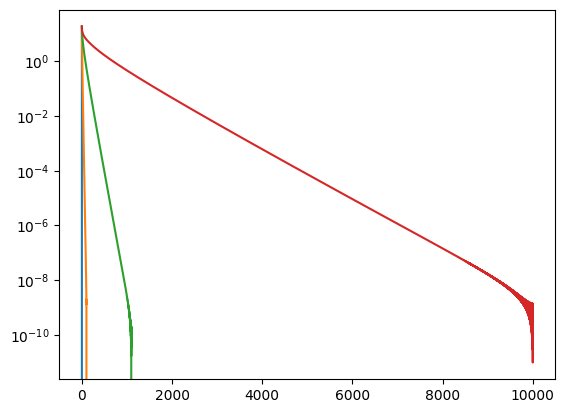

In [9]:
import matplotlib.pyplot as plt

error_list = []
for res in results:
    errors = np.array([np.linalg.norm(xk - res.x) for xk in res.history["x"]])
    error_list.append(errors)
    plt.semilogy(errors)

In [10]:
for err in error_list:
    print(err.shape)

(2,)
(103,)
(1097,)
(10000,)


In [11]:
def calc_r(k):
    return (k-1)/(k+1)

def fit_r(errors, lo_frac=0.2, hi_frac=1.0):
    e = np.asarray(errors, dtype=float)

    # 1) önce sadece sonlu ve kesin pozitif olanları al
    ok = np.isfinite(e) & (e > 0)
    if ok.sum() < 5:
        return np.nan

    e0 = e[ok][0]
    # 2) makine tabanını e0'a göre ele
    ok &= e > 1e-13 * e0

    k = np.arange(e.size)
    idx = np.flatnonzero(ok)
    lo = idx[int(lo_frac * idx.size)]
    hi = idx[min(int(hi_frac * idx.size), idx.size - 1)]

    m = ok.copy()
    m[:lo] = False
    m[hi+1:] = False

    if m.sum() < 5:
        return np.nan

    y = np.log(e[m])
    if not np.all(np.isfinite(y)):          # son savunma
        return np.nan

    slope = np.polyfit(k[m], y, 1)[0]
    return np.exp(slope)
    
slope = [calc_r(10), calc_r(100), calc_r(1000)]
r_expr = [] 

for err in error_list:
    if err.size > 30:
        r = fit_r(err)
        r_expr.append(float(r))

print(slope)
print(r_expr)

[0.8181818181818182, 0.9801980198019802, 0.998001998001998]
[0.8081919700379505, 0.9789984494067194, 0.9978661700273759]


# 1.4

In [15]:
from optlib.line_search import BacktrackingLineSearch

rosen = Rosenbrock2d(a=1, b=100)
bls = BacktrackingLineSearch(rho=0.5, c=1e-4, alpha0=1.0)
x0 = np.array([-1.2, 1.0])
res_bls = bls.minimize(rosen, x0=x0.copy(), tol=1e-6, max_iter=10000)

print(f"Bactracking LS n_iter: {res_bls.n_iter}")
print(f"CONVERGED: {res_bls.converged}")

Bactracking LS n_iter: 8664
CONVERGED: True


In [17]:
alpha_set = [1e-2, 1e-3, 1e-4, 1e-5]
result_set = []  
for alpha in alpha_set:
    gd = GD(alpha)
    res = gd.minimize(rosen, x0.copy(), tol=1e-6, max_iter=100000)
    result_set.append(res)

for alpha, res in zip(alpha_set, result_set):
    print(f"Step length: {alpha}")
    print(f"Steepest n_iter: {res.n_iter}")
    print(f"CONVERGED: {res.converged}")
    print("-----")

/home/alper/workspace/optlib/notebooks/../problems/testfuncs.py:36: RuntimeWarning: overflow encountered in scalar power
  return (a - x)**2 + b*(y - x**2)**2
/home/alper/workspace/optlib/notebooks/../problems/testfuncs.py:41: RuntimeWarning: overflow encountered in scalar power
  return np.array([(-2 * (a - x)) + (2 * b*(y - x**2) * (-2*x)),
/home/alper/workspace/optlib/notebooks/../problems/testfuncs.py:42: RuntimeWarning: overflow encountered in scalar power
  2 * b*(y - x**2)])
/home/alper/workspace/optlib/notebooks/../problems/testfuncs.py:36: RuntimeWarning: invalid value encountered in scalar subtract
  return (a - x)**2 + b*(y - x**2)**2
/home/alper/workspace/optlib/notebooks/../problems/testfuncs.py:41: RuntimeWarning: invalid value encountered in scalar subtract
  return np.array([(-2 * (a - x)) + (2 * b*(y - x**2) * (-2*x)),
/home/alper/workspace/optlib/notebooks/../problems/testfuncs.py:42: RuntimeWarning: invalid value encountered in scalar subtract
  2 * b*(y - x**2)])


Step length: 0.01
Steepest n_iter: 99999
CONVERGED: False
-----
Step length: 0.001
Steepest n_iter: 32076
CONVERGED: True
-----
Step length: 0.0001
Steepest n_iter: 99999
CONVERGED: False
-----
Step length: 1e-05
Steepest n_iter: 99999
CONVERGED: False
-----


# 1.5